# Question 2 — Motion or Memory?

ConvLSTM forecasters on Moving MNIST, stress-tested with mirror, rotation and speed-up.
The logic lives in the scripts next to this notebook (`common.py`, `checks.py`, `flow.py`, `train.py`,
`evaluate.py`); each cell runs one script and shows its tables and figures.

Training cells skip a model whose checkpoint already exists, so you can re-run the notebook safely.
One 30-epoch run takes about 25 minutes on an Apple M1 GPU.

**Q2.5 and Q2.11 must be written and committed before the experiments they predict.**

In [1]:
import sys
from pathlib import Path
from IPython.display import Image, Markdown, display

PY = sys.executable
RESULTS = Path("results")


def table(n):
    display(Markdown((RESULTS / f"table{n}.md").read_text()))


def figure(name):
    display(Image(filename=str(RESULTS / name)))


def run(script, *args):
    get_ipython().system(f'"{PY}" {script} {" ".join(map(str, args))}')


def train(model, seed, *extra):
    """Train one model and seed unless its checkpoint already exists."""
    name = extra[extra.index("--name") + 1] if "--name" in extra else model
    if Path(f"checkpoints/{name}_s{seed}.pt").exists():
        print(f"{name} seed {seed}: checkpoint exists, skipping")
        return
    run("train.py", model, "--seed", seed, *extra)

## 1. Setup

### Table 1 — checking the code

In [2]:
run("checks.py")
table(1)

| Check | Expected | Yours |
|---|---|---|
| (a) max\|M(M(x)) - x\| | 0 | 0 (torch.equal: True) |
| (b) max\|R^4(x) - x\| | 0 | 0 (torch.equal: True) |
| (c) max\|MRM(x) - R^{-1}(x)\| | 0 | 0 (torch.equal: True) |
| (d) bright pixel of M(p) | (7, 10, 43) | (7, 10, 43) |
| (e) bright pixel of R(p) | (7, 43, 10) | (7, 43, 10) |
| (f) 1x input / target frames | 1-5 / 6-10 | 1, 2, 3, 4, 5 / 6, 7, 8, 9, 10 |
| (g) 2x input / target frames | 1, 3, 5, 7, 9 / 11, 13, 15, 17, 19 | 1, 3, 5, 7, 9 / 11, 13, 15, 17, 19 |
| (h) 3x input / target frames | 1, 4, 7, 10, 13 / 16, 19 | 1, 4, 7, 10, 13 / 16, 19 |


**Table 1.** Transformation and window checks.

| Check | Expected | Yours |
|---|---|---|
| (a) max\|M(M(x)) - x\| | 0 | 0 (torch.equal: True) |
| (b) max\|R^4(x) - x\| | 0 | 0 (torch.equal: True) |
| (c) max\|MRM(x) - R^{-1}(x)\| | 0 | 0 (torch.equal: True) |
| (d) bright pixel of M(p) | (7, 10, 43) | (7, 10, 43) |
| (e) bright pixel of R(p) | (7, 43, 10) | (7, 43, 10) |
| (f) 1x input / target frames | 1-5 / 6-10 | 1, 2, 3, 4, 5 / 6, 7, 8, 9, 10 |
| (g) 2x input / target frames | 1, 3, 5, 7, 9 / 11, 13, 15, 17, 19 | 1, 3, 5, 7, 9 / 11, 13, 15, 17, 19 |
| (h) 3x input / target frames | 1, 4, 7, 10, 13 / 16, 19 | 1, 4, 7, 10, 13 / 16, 19 |


### Figure 1 — is the training data already symmetric?

{
  "pixels_kept": 103050,
  "median_speed": 3.317502498626709,
  "median_2x": 6.635004997253418,
  "median_3x": 9.952507495880127,
  "direction_fractions": {
    "0": 0.049,
    "20": 0.0488,
    "40": 0.0675,
    "60": 0.0731,
    "80": 0.0602,
    "100": 0.0561,
    "120": 0.0263,
    "140": 0.0326,
    "160": 0.0384,
    "180": 0.082,
    "200": 0.0642,
    "220": 0.0541,
    "240": 0.0666,
    "260": 0.0614,
    "280": 0.0571,
    "300": 0.0366,
    "320": 0.0487,
    "340": 0.0772
  }
}


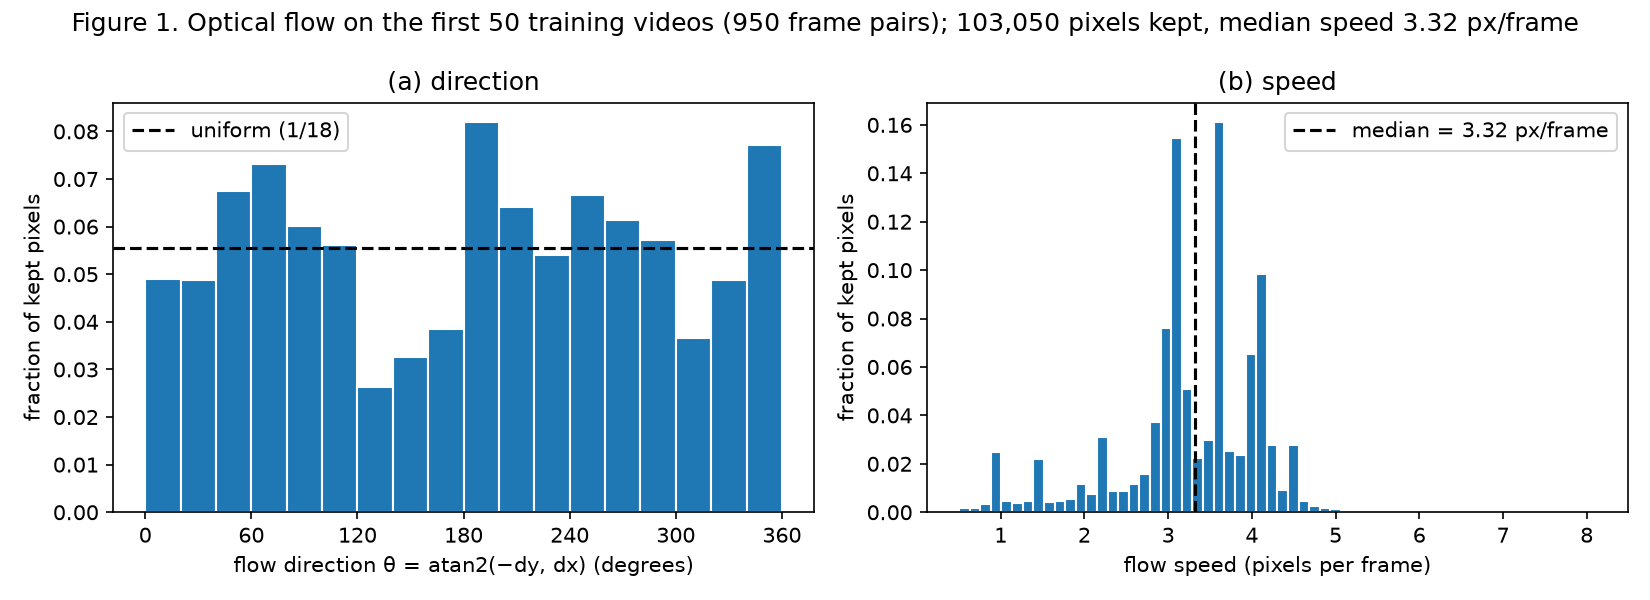

In [3]:
run("flow.py")
figure("fig1_flow.png")

**Q2.1** Would mirrored and rotated trajectories already be familiar? Typical speed, and what are 2× and 3× in px/frame? Could overlap bias the histograms?

**Direction.** Yes, mirrored and rotated trajectories should already be familiar. Figure 1(a) has no empty bins: every 20° bin holds between 2.6% (120°–140°) and 8.2% (180°–200°) of the kept pixels, against 5.6% for a uniform distribution. Mirroring maps a direction θ to 180° − θ, so the mirrored histogram is Figure 1(a) reflected about 90° (the 180°–200° peak moves to 340°–360°, which already holds 7.7%). A 90° rotation maps θ to θ + 90°, which simply shifts the histogram. Either way, every direction in the transformed videos is one the model has seen at least 2.6% of the time. The histogram is uneven mainly because 50 videos contain only 100 digits, each moving in one direction between bounces.

**Speed.** The median speed is 3.32 px/frame, and almost all kept pixels lie between about 3 and 4.5 px/frame (peaks near 3.1, 3.6 and 4.1), with essentially nothing above 5 px/frame. At 2× the median becomes 6.64 px/frame and at 3× it becomes 9.95 px/frame, so typical motion at 2× and 3× is faster than anything in the training data.

**Overlap.** Where digits overlap, Farneback's 15-pixel window averages the motion of both digits, so those pixels get a blended direction and usually a smaller speed. This adds some weight to the low-speed tail and to directions between the two digits' true directions. It cannot change the answer: overlap does not create directions that are not there, and biasing speeds downward only widens the gap between the training speeds and 2× or 3×.

**Q2.2** Does each transformation change motion statistics, digit appearance, or both? Why is this a controlled experiment?

- **Mirror:** changes digit appearance (a mirrored 2 is not a digit) but keeps speed, and it only reflects directions within a range the training data already covers (Q2.1). In practice it changes appearance only.
- **Rotation:** the same, with a stronger change in appearance, since vertical strokes become horizontal for every digit. The motion statistics are again familiar.
- **Speed-up:** keeps every digit's appearance (the frames themselves are untouched) but multiplies the displacement between frames by k, so it changes the motion statistics only.

This makes a controlled experiment because each transformation moves one factor while holding the other fixed, and all three keep the scene physically valid, so the correct answer T(Y) is known exactly. A model that has learned the motion rule should pass all three. If it fails mirror and rotation but not speed, the problem is appearance; if it fails speed but not mirror and rotation, the problem is motion.

## 2. Baseline: ConvLSTM (model A)

In [4]:
train("A", 0)
train("A", 1)

A seed 0: checkpoint exists, skipping
A seed 1: 480,784 params, reach 8 px, speed aug False, symmetry aug False, macOS-15.0-arm64-arm-64bit-Mach-O (mps)
epoch  1  train 0.0477  val E5 0.0394  50.9s
epoch  2  train 0.04  val E5 0.0391  47.0s
epoch  3  train 0.0396  val E5 0.0387  47.7s
epoch  4  train 0.0392  val E5 0.038  46.3s
epoch  5  train 0.0375  val E5 0.0358  46.3s
epoch  6  train 0.0352  val E5 0.0338  46.1s
epoch  7  train 0.0333  val E5 0.032  46.3s
epoch  8  train 0.032  val E5 0.0308  46.9s
epoch  9  train 0.0308  val E5 0.03  48.5s
epoch 10  train 0.03  val E5 0.0292  48.8s
epoch 11  train 0.0292  val E5 0.0294  48.1s
epoch 12  train 0.0285  val E5 0.0278  47.4s
epoch 13  train 0.0279  val E5 0.0278  48.2s
epoch 14  train 0.0273  val E5 0.0269  48.7s
epoch 15  train 0.0267  val E5 0.0263  48.9s
epoch 16  train 0.0262  val E5 0.0258  48.8s
epoch 17  train 0.0257  val E5 0.0256  47.5s
epoch 18  train 0.0254  val E5 0.0254  47.0s
epoch 19  train 0.0249  val E5 0.0246  46.1s
e

**Table 2.** Per-horizon test MSE (mean (seed 0, seed 1) for model A).

| Model | MSE1 | MSE2 | MSE3 | MSE4 | MSE5 | E(5) | params |
|---|---|---|---|---|---|---|---|
| A | 0.0171 (0.0176, 0.0166) | 0.0205 (0.021, 0.0199) | 0.0227 (0.0233, 0.0221) | 0.0245 (0.0251, 0.0239) | 0.0262 (0.0267, 0.0256) | 0.0222 (0.0227, 0.0216) | 480,784 |
| Blank | 0.0426 | 0.0426 | 0.0426 | 0.0425 | 0.0425 | 0.0426 | 0 |
| Copy-last | 0.0492 | 0.0604 | 0.0669 | 0.0708 | 0.0732 | 0.0641 | 0 |

Figure 2 videos: [7, 12, 10] (last one has overlapping digits)
saved /Users/Israr/Documents/.personal/Lums/S03 - AI 651/Assignments/DL4STG_PA2/Question2/results/fig2_predictions.png
Model A reach: 8 px; hardware: macOS-15.0-arm64-arm-64bit-Mach-O (mps)


**Table 2.** Per-horizon test MSE (mean (seed 0, seed 1) for model A).

| Model | MSE1 | MSE2 | MSE3 | MSE4 | MSE5 | E(5) | params |
|---|---|---|---|---|---|---|---|
| A | 0.0171 (0.0176, 0.0166) | 0.0205 (0.021, 0.0199) | 0.0227 (0.0233, 0.0221) | 0.0245 (0.0251, 0.0239) | 0.0262 (0.0267, 0.0256) | 0.0222 (0.0227, 0.0216) | 480,784 |
| Blank | 0.0426 | 0.0426 | 0.0426 | 0.0425 | 0.0425 | 0.0426 | 0 |
| Copy-last | 0.0492 | 0.0604 | 0.0669 | 0.0708 | 0.0732 | 0.0641 | 0 |


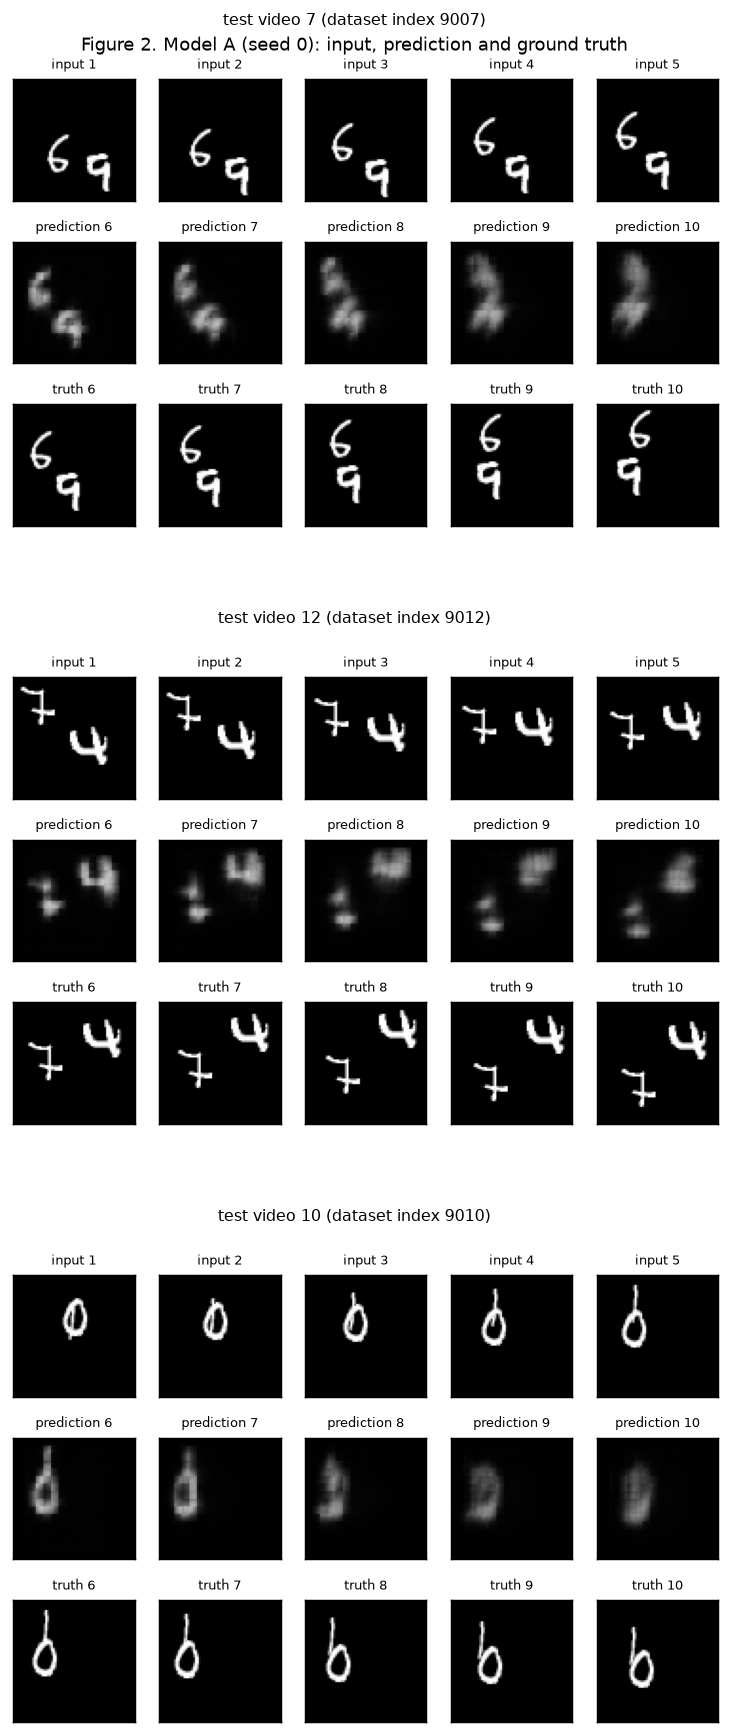

In [5]:
run("evaluate.py", "baseline")
table(2)
figure("fig2_predictions.png")

**Q2.3** Model A's reach in original pixels per time step.

**Model A's reach is 8 original pixels per time step.**

- After `pixel_unshuffle(x, 4)` each position of the 16×16 grid is one 4×4 patch, so moving one grid cell moves 4 original pixels.
- A 3×3 convolution (stride 1, padding 1) lets each output cell see its immediate neighbours, so one pass moves information by at most 1 cell = 4 px.
- Within one step τ the only spatial operations are the two gate convolutions. Everything else (the sigmoids, tanh, the elementwise cell update c, the 1×1 output convolution and the pixel shuffles) acts on one position at a time.
- Possible paths to x̂τ+1:
  - from the new input uτ: layer-1 convolution (1 cell), then layer-2 convolution on hτ⁽¹⁾ (1 cell) = 2 cells;
  - from hτ−1⁽¹⁾: it enters the same layer-1 convolution as uτ, so again 2 cells;
  - from hτ−1⁽²⁾: only the layer-2 convolution, 1 cell.
- The cell states c⁽¹⁾ and c⁽²⁾ are updated elementwise, so a path that starts in cτ−1⁽¹⁾ passes through at most the layer-2 convolution (1 cell), and one that starts in cτ−1⁽²⁾ through none. They do not change the answer.
- The longest path is 2 cells × 4 px = **8 px** centre-to-centre along a row or column. Along a diagonal the same 2 cells reach 2√2 × 4 ≈ 11.3 px in straight-line distance. Flow speeds are straight-line distances, so I use the conservative 8 px when comparing reach with speed.

The recurrence does not add reach within one step, since states pass to the next step without any spatial mixing. It does let information keep travelling another 8 px at every step, so over the 5 input steps the network can integrate motion over a larger area, but it can link a digit's old position (in the state) to its new position (in the input) only within 8 px per update.

**Q2.4** Model A vs Blank and Copy-last; error growth over horizons; overlapping digits.

**Against the references.** Model A has E(5) = 0.0222 (0.0227, 0.0216), about half of Blank (0.0426) and a third of Copy-last (0.0641), and it beats both at every horizon. Copy-last is even worse than Blank because a digit drawn in the wrong place is penalised twice: once where it is drawn and once where it should be. So model A is not just copying frames; it moves the digits.

**Over the horizons.** Model A's error rises from MSE₁ = 0.0171 to MSE₅ = 0.0262 (+53%), with each step adding a little less (+0.00338, +0.00225, +0.00179, +0.00167). Blank stays flat at 0.0426, and Copy-last grows faster (0.0492 to 0.0732) as the digits move further from where it left them. Figure 2 shows why model A's error grows: the digits sit roughly in the right places but get blurrier with every step, and by frame 10 they are grey blobs. Under squared error, a blurred digit is the safest guess when the position is uncertain, and the model then feeds its own blurry predictions back as input.

**Overlap.** In test video 7 the 6 moves up towards the 9, and the predictions merge the two into one vertical smear by frames 8–10 instead of keeping two digits. In test video 10 the two digits overlap almost completely at the start; the model predicts a single blob, and the second digit's stroke disappears by frame 8. When digits overlap, model A loses the separate identity of each one.

**Q2.5** *Written before running any experiment in Testing the Baseline; not edited afterwards.*

Will model A pass the mirror test? The rotation test? At what speed should it break down?

**Mirror — partial pass.** Figure 1(a) shows flow in every direction (all 18 bins are occupied, between about 0.026 and 0.082), so mirrored trajectories (θ → 180° − θ) are familiar motion. Mirrored digits are unfamiliar shapes, though. I expect model A to move the mirrored digits to roughly the right places but to render them less sharply, so C_M and E_M will be small but clearly above zero, with E_M somewhat larger than E(5).

**Rotation — weaker pass than mirror.** A 90° rotation (θ → θ + 90°) also maps onto directions seen in training, so the motion should still be familiar. Rotated digits are further from anything in training than mirrored ones (a rotated 1 is a horizontal bar). I therefore predict C_R > C_M and E_R > E_M, with the extra error coming from appearance rather than from the motion.

**Speed — degrades at 2×, breaks down at 3×.** Model A's reach is 8 px per step (two 3×3 convolutions, each moving one 4-pixel cell). The median speed is 3.3 px/frame, so 2× ≈ 6.6 px is inside the reach but close to its edge, and the fastest digits (≈ 5 px/frame at 1×) exceed it. 3× ≈ 10 px/frame is beyond the reach for most digits. I predict E(2) rises noticeably at 2×, and that at 3× the predictions fall apart: digits blur, stall near their last position or vanish, giving errors close to or worse than Copy-last.

## 3. Testing the baseline

### Mirror and rotation — Tables 3 and 4, Figures 3–5

**Table 3.** Error and consistency under mirror (M) and rotation (R), 1x, t = 1.

| Model | E(5) | C_M | E_M | C_R | E_R |
|---|---|---|---|---|---|
| A | 0.0222 (0.0227, 0.0216) | 0.00193 (0.00199, 0.00187) | 0.0228 (0.0234, 0.0222) | 0.00317 (0.00318, 0.00316) | 0.0239 (0.0244, 0.0234) |
| Blank | 0.0426 | 0 | 0.0426 | 0 | 0.0426 |
| Copy-last | 0.0641 | 0 | 0.0641 | 0 | 0.0641 |

**Table 4.** Faster motion, t = 1.

| Model | E(2) 1x | E(2) 2x | E(2) 3x | E(5) 1x | E(5) 2x |
|---|---|---|---|---|---|
| A | 0.0188 (0.0193, 0.0183) | 0.0455 (0.0449, 0.0462) | 0.053 (0.052, 0.0539) | 0.0222 (0.0227, 0.0216) | 0.0507 (0.0504, 0.0511) |
| Copy-last | 0.0548 | 0.0661 | 0.0703 | 0.0641 | 0.0719 |

saved /Users/Israr/Documents/.personal/Lums/S03 - AI 651/Assignments/DL4STG_PA2/Question2/results/fig3_consistency.png
saved /Users/Israr/Documents/.personal/Lums/S03 - AI 651/Assignments/DL4STG_PA2/Question2/results/fig4_consistency_hist.png
saved /Users/Israr/Documents/.personal/Lums/S03 - AI 65

**Table 3.** Error and consistency under mirror (M) and rotation (R), 1x, t = 1.

| Model | E(5) | C_M | E_M | C_R | E_R |
|---|---|---|---|---|---|
| A | 0.0222 (0.0227, 0.0216) | 0.00193 (0.00199, 0.00187) | 0.0228 (0.0234, 0.0222) | 0.00317 (0.00318, 0.00316) | 0.0239 (0.0244, 0.0234) |
| Blank | 0.0426 | 0 | 0.0426 | 0 | 0.0426 |
| Copy-last | 0.0641 | 0 | 0.0641 | 0 | 0.0641 |


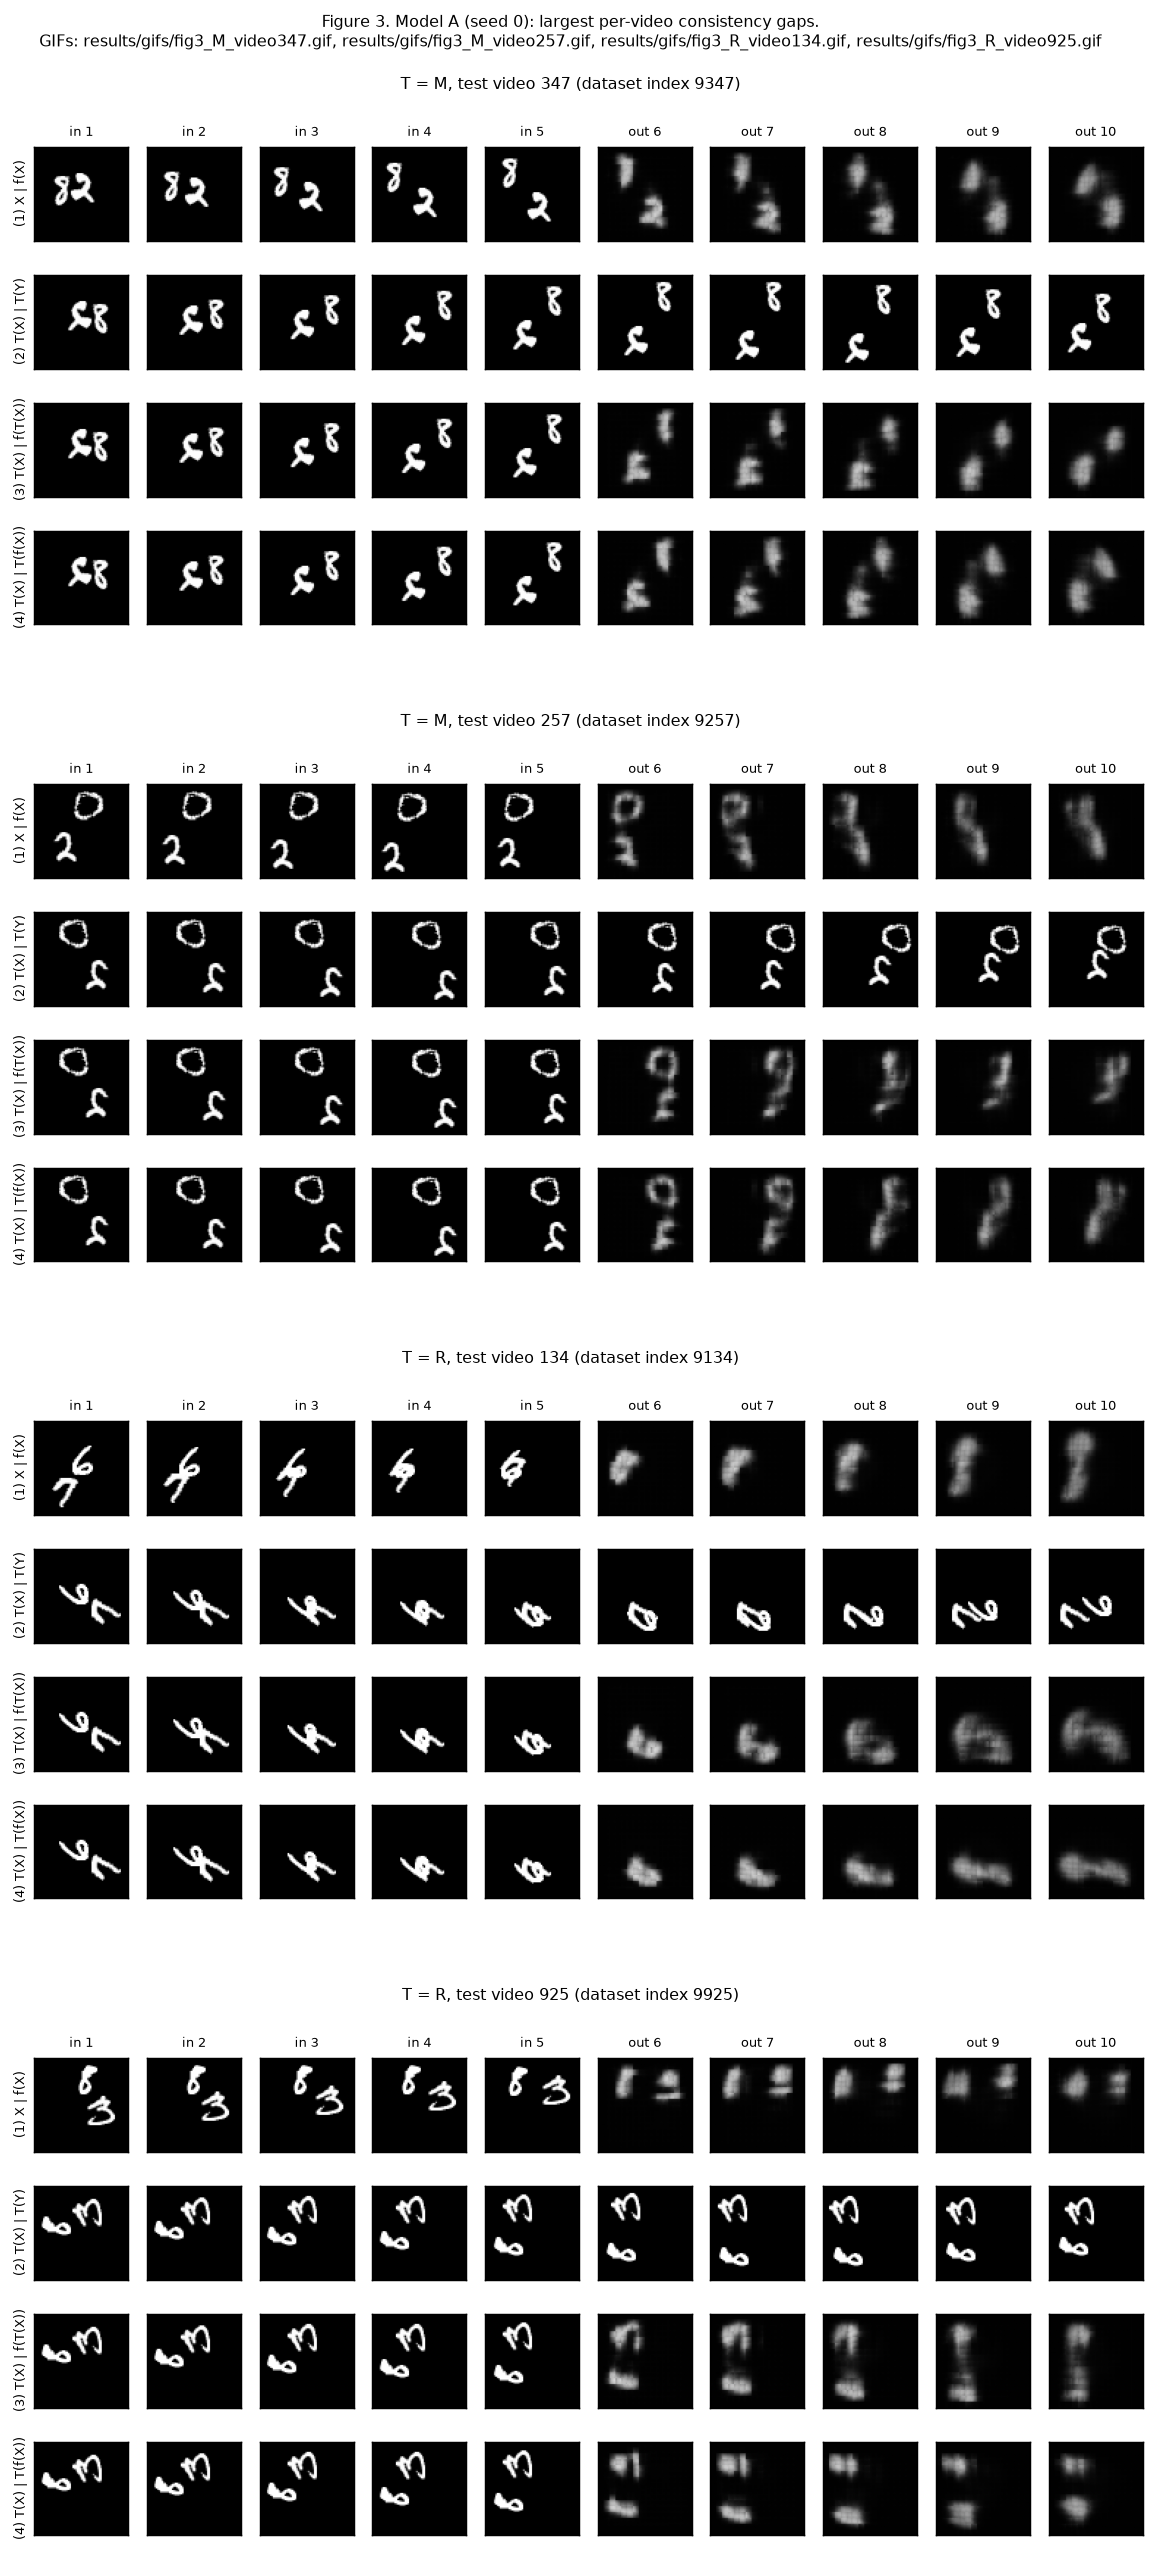

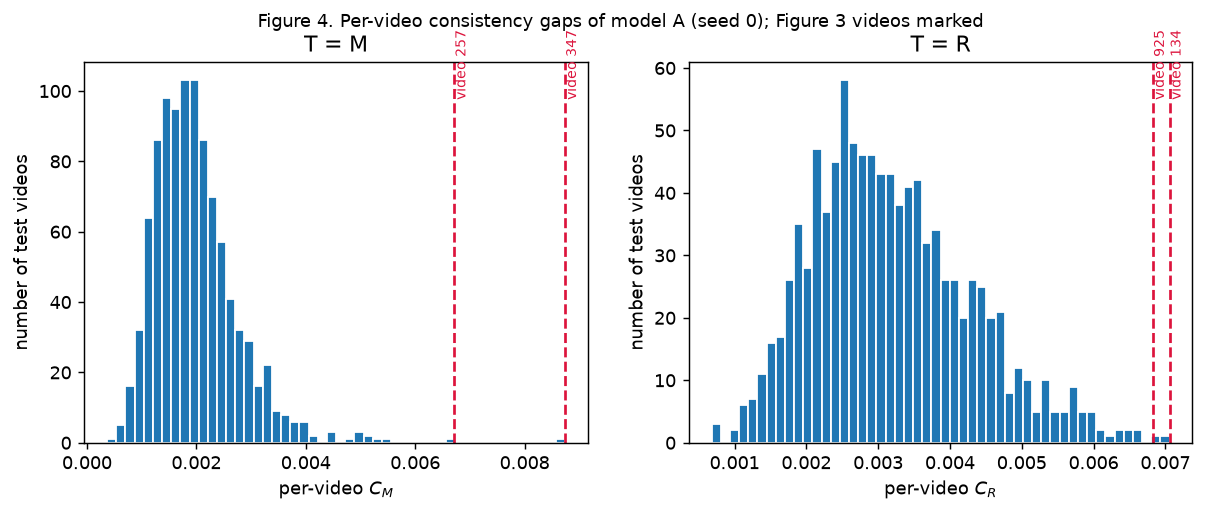

In [6]:
run("evaluate.py", "stress")
table(3)
figure("fig3_consistency.png")
figure("fig4_consistency_hist.png")

**Q2.6** Blank and Copy-last are exactly consistent — what does this say about reading C_T alone?

Blank and Copy-last have C_M = C_R = 0 but E_M = E_R = 0.0426 and 0.0641, both worse than model A. A forecaster that ignores the motion (outputs nothing, or repeats the last frame) commutes with any pixel rearrangement, so it is perfectly consistent and still wrong. A small C_T therefore cannot tell "moves things correctly in every orientation" apart from "does not really move things at all"; a model that blurs everything towards a blank frame would also score well. E_T measures what we actually want, whether the transformed prediction matches the transformed truth, so C_T is only meaningful next to E_T (and next to E(5) on the original clips).

**Q2.7** One Figure 3 video where rows 3 and 4 disagree: how does the model's account of the motion change?

**Test video 925, rotation (second-largest per-video C_R, 0.00683; per-video E_R 0.0357 against the test mean of 0.0239).** In the original video an 8 and a 3 sit side by side near the top and barely move. After rotation they are stacked vertically: the rotated 3 at the top and the rotated 8 at the lower left. In the truth (row 2) the two stay well apart for all five future frames.

- **Row 4, T(f(X)):** model A's prediction on the original video, rotated. It keeps two separate blobs, one above the other, through frame 10. The layout is right and the digits are just blurred.
- **Row 3, f(T(X)):** what model A predicts when it sees the rotated video. The top digit loses its shape and becomes a tall vertical smear that stretches downward, while the lower digit stays a blob. By frames 9–10 the gap between them has closed and they form one vertical streak.

So in the rotated scene the model's account of the motion changes from "two digits staying apart" to "the top digit drifting down into the bottom one". The upper digit is effectively lost into the lower one, even though the true motion is the same as in the original video turned by 90°.

**Q2.8** Is rotation harder than mirroring for model A — motion or appearance?

Yes. Model A's rotation gap is larger than its mirror gap for both seeds: C_R = 0.00317 against C_M = 0.00193 (about 1.6 times larger), and E_R = 0.0239 against E_M = 0.0228, with E(5) = 0.0222. Figure 4 shows the same thing: the per-video C_R histogram is wider and sits further right than the C_M histogram.

The difference comes from appearance, not motion. Q2.1 showed that mirrored and rotated directions are both well covered by the training data, and neither transformation changes speed (Q2.2), so the motion is equally familiar in both tests. What differs is how far the digits move from anything seen in training: several digits (0, 1, 8) look almost the same when mirrored, while a 90° rotation turns the vertical strokes of every digit horizontal, for example making a 1 a horizontal bar. Model A's motion rule appears to be tied to what upright digits look like. Table 5 later supports this: training with symmetry augmentation (model B) brings E_R down to 0.0221, equal to its E(5).

### Faster motion

**Table 4.** Faster motion, t = 1.

| Model | E(2) 1x | E(2) 2x | E(2) 3x | E(5) 1x | E(5) 2x |
|---|---|---|---|---|---|
| A | 0.0188 (0.0193, 0.0183) | 0.0455 (0.0449, 0.0462) | 0.053 (0.052, 0.0539) | 0.0222 (0.0227, 0.0216) | 0.0507 (0.0504, 0.0511) |
| Copy-last | 0.0548 | 0.0661 | 0.0703 | 0.0641 | 0.0719 |


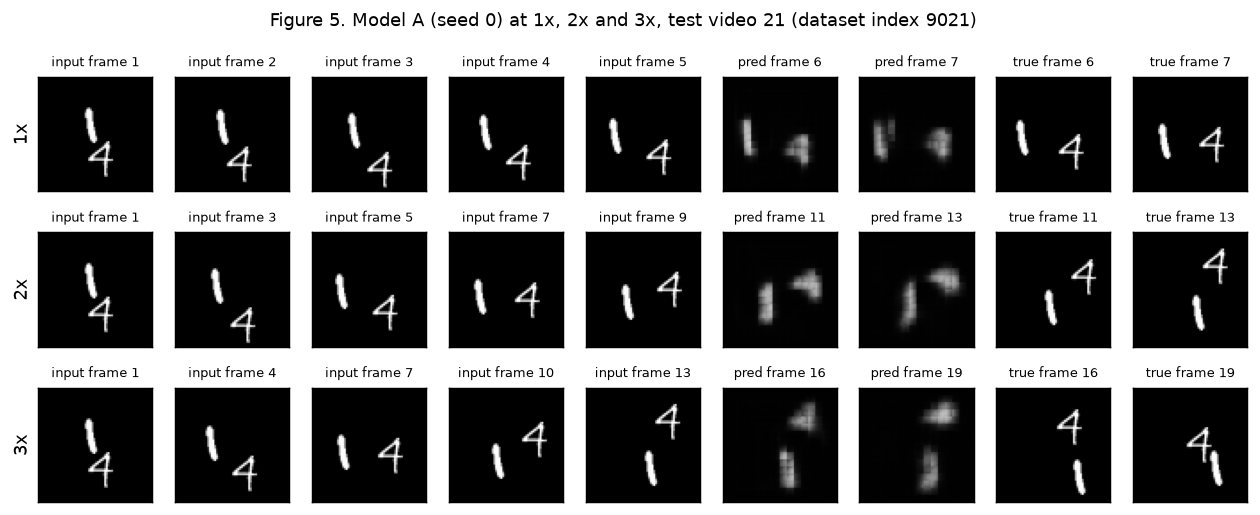

In [7]:
table(4)
figure("fig5_speed.png")

**Q2.9** At what speed does model A fall apart; does it match the reach from Q2.3? What does the failure look like?

**Model A falls apart at 2×.** Its E(2) rises from 0.0188 at 1× to 0.0455 at 2× and 0.0530 at 3× (Table 4). Both are worse than predicting a blank frame (Blank E(2) = 0.0425 at 2× and 0.0426 at 3×, Table 4), though still better than Copy-last (0.0661 and 0.0703). At 2× the model has already gone from beating Blank by more than half to doing worse than Blank.

**This does not match the reach estimate.** Q2.3 gives 8 px per step, and the typical 2× speed is 6.6 px/frame, inside that reach, so reach alone would predict that 2× is still manageable (this is also what I predicted in Q2.5). What the estimate misses is that reach is only an upper bound on what the network could connect. It says nothing about what it learned to do. Model A was trained only on speeds up to about 5 px/frame, so its learned update does not follow displacements larger than that, whatever the inputs show.

**What the failure looks like (Figure 5, test video 74: two 1s that stay at least about 7 px apart in every frame shown).** At 1× the predicted digits sit where the true ones are, just blurred: the upper 1 is predicted at column 25.0, row 16.5 against 25.0, 16.3 in the truth. At 2× and 3× the predicted digits stall. Measured by blob centroids, they move only 1–5 px away from their positions in the last input frame, while the true digits move 6–15 px. At 3× they barely move at all (under 2.5 px in both predicted frames), so frame 19 still shows the digits near where they were in frame 13, while the true digits have bounced and moved closer together. Both digits are also smeared into blobs. There are no duplicated digits, and nothing vanishes. Stalling suggests the model does not use the displacement it observed between input frames, which is larger than anything it was trained on, and falls back to keeping each digit close to its last position. Blurring suggests it is unsure where the digits are and hedges by spreading intensity over the possible positions.

**Q2.10** Unfamiliar fast motion or beyond reach? Propose an experiment that tells them apart.

No. Fast motion never appeared in training (Figure 1(b) has almost nothing above 5 px/frame), and it also approaches or exceeds the reach, so both explanations predict the failure we see, and model A alone cannot separate them. The 2× failure at 6.6 px/frame, inside the 8 px reach, points towards unfamiliar motion, but the reach is only an estimate of an upper bound, so this is not conclusive.

**Experiment.** Change one factor at a time:
1. Train the same architecture (8 px reach) with speed augmentation, so 2× and 3× motion becomes familiar. If its 2× and 3× errors drop to near its 1× error, the failure was unfamiliar motion.
2. Train an architecture with a strictly larger reach on the same speed-augmented data. If it does clearly better at 3× than step 1, the remaining failure is architectural reach.
(Optionally, also train the larger-reach model at 1× only; if it still fails at 2× and 3×, more reach without the data does not help.) Steps 1 and 2 are exactly models C and D.

## 4. What can data fix?

### Choosing model D (validation split only)
Short runs of each candidate; compare the `validation:` line printed at the end of each run
(E5 at 1×, E2_3 at 3×). The next cell picks the winner automatically (lowest mean val E(2) over the three speeds).

| Candidate | Change from A | Params | Reach |
|---|---|---|---|
| `k5` | 5×5 kernels, 44 channels | 652,272 | 16 px |
| `dil` | second layer dilation 2 | 480,784 | 12 px |
| `p8` | 8×8 patches | 594,496 | 16 px |

In [8]:
for arch in ("k5", "dil", "p8"):
    train("D", 0, "--arch", arch, "--epochs", 5, "--name", f"D-{arch}-short")

D-k5-short seed 0: 652,272 params, reach 16 px, speed aug True, symmetry aug False, macOS-15.0-arm64-arm-64bit-Mach-O (mps)
epoch  1  train 0.0468  val E5 0.0395  124.8s
epoch  2  train 0.0402  val E5 0.0395  118.3s
epoch  3  train 0.0402  val E5 0.0395  118.4s
epoch  4  train 0.0402  val E5 0.0395  118.4s
epoch  5  train 0.0402  val E5 0.0395  118.5s
validation: MSE1 0.0395  MSE2 0.0395  MSE3 0.0395  MSE4 0.0395  MSE5 0.0394  E5 0.0395  E2_1 0.0395  E5_2 0.0395  E2_2 0.0395  E2_3 0.0395  CM 2.17e-08  EM 0.0395  CR 4.66e-08  ER 0.0395
D-dil-short seed 0: 480,784 params, reach 12 px, speed aug True, symmetry aug False, macOS-15.0-arm64-arm-64bit-Mach-O (mps)
epoch  1  train 0.0465  val E5 0.0392  59.9s
epoch  2  train 0.0397  val E5 0.0389  58.9s
epoch  3  train 0.0394  val E5 0.0384  58.6s
epoch  4  train 0.0386  val E5 0.0373  58.6s
epoch  5  train 0.0378  val E5 0.0364  58.5s
validation: MSE1 0.0354  MSE2 0.036  MSE3 0.0366  MSE4 0.0369  MSE5 0.0372  E5 0.0364  E2_1 0.0357  E5_2 0.03

In [ ]:
import torch
# Pick D on the validation split: lowest mean of E(2) at 1x, 2x and 3x (equal weight to every speed).
scores = {}
for arch in ("k5", "dil", "p8"):
    val = torch.load(f"checkpoints/D-{arch}-short_s0.pt", weights_only=False)["val"]
    scores[arch] = (val["E2_1"] + val["E2_2"] + val["E2_3"]) / 3
    print(f"{arch:4s} val E5 1x {val['E5']:.3g}   E2 1x {val['E2_1']:.3g}   E2 2x {val['E2_2']:.3g}   "
          f"E2 3x {val['E2_3']:.3g}   mean E2 {scores[arch]:.3g}")
D_ARCH = min(scores, key=scores.get)
print("chosen D architecture:", D_ARCH)

k5   val E5 1x 0.0395   E2 1x 0.0395   E2 2x 0.0395   E2 3x 0.0395   mean E2 0.0395
dil  val E5 1x 0.0364   E2 1x 0.0357   E2 2x 0.0363   E2 3x 0.0372   mean E2 0.0364
p8   val E5 1x 0.0395   E2 1x 0.0395   E2 2x 0.0395   E2 3x 0.0395   mean E2 0.0395
chosen D architecture: dil


: 

**Q2.11** *Written before training B–D; not edited afterwards.*

Which model will fix which failure (at most three sentences)?

Model B (symmetry augmentation, 1× only) will shrink C_M and C_R and bring E_M and E_R close to E(5), helping most on rotation because that gap comes mainly from unfamiliar digit appearance; it will not help at 2× or 3×. Model C (speed augmentation) will clearly reduce E(2) at 2×, where about 6.6 px/frame is still inside model A's 8 px reach, but only partly at 3×, where most motion exceeds that reach, and it will leave the mirror and rotation gaps roughly as in model A. Model D (larger reach plus speed augmentation) will fix the remaining 3× failure, beating C at 3× while matching it at 1× and 2×, with consistency gaps similar to A's because it sees no symmetry augmentation.

### Train B, C, D (two seeds each) — about 2.5 hours

In [ ]:
for m in ("B", "C", "D"):
    for s in (0, 1):
        train(m, s, "--arch", D_ARCH)

B seed 0: 480,784 params, reach 8 px, speed aug False, symmetry aug True, macOS-15.0-arm64-arm-64bit-Mach-O (mps)
epoch  1  train 0.0461  val E5 0.0393  53.0s
epoch  2  train 0.0397  val E5 0.0385  52.1s
epoch  3  train 0.0387  val E5 0.0373  52.1s
epoch  4  train 0.0371  val E5 0.0355  52.1s
epoch  5  train 0.0354  val E5 0.0338  52.1s
epoch  6  train 0.0336  val E5 0.0323  52.0s
epoch  7  train 0.0323  val E5 0.0313  52.1s
epoch  8  train 0.0313  val E5 0.0308  52.2s
epoch  9  train 0.0303  val E5 0.0297  52.1s
epoch 10  train 0.0298  val E5 0.0291  52.1s
epoch 11  train 0.0292  val E5 0.0286  52.1s
epoch 12  train 0.0287  val E5 0.0283  52.1s
epoch 13  train 0.0282  val E5 0.0278  52.1s
epoch 14  train 0.0278  val E5 0.0273  52.1s
epoch 15  train 0.0274  val E5 0.0271  52.1s
epoch 16  train 0.0271  val E5 0.0267  52.1s
epoch 17  train 0.0267  val E5 0.0262  52.2s
epoch 18  train 0.0262  val E5 0.0259  52.6s
epoch 19  train 0.0258  val E5 0.0255  49.4s
epoch 20  train 0.0255  val E5 

### Table 5

In [ ]:
run("evaluate.py", "compare")
table(5)

**Q2.12** Describe model D and estimate its reach, showing it is strictly larger than model A's.

**Model D** is model A with **dilation 2 in the second ConvLSTM layer** (3×3 kernel, padding 2). Everything else is identical to model A: 4×4 patch folding, 64 hidden channels in both layers, 3×3 kernels, the 1×1 output convolution, the 9-step rollout without teacher forcing, and the training protocol with speed augmentation (k drawn uniformly from {1, 2, 3}). Dilation adds no weights, so D has 480,784 parameters, the same as A and well under the 721,176 limit.

**Reach.** Same convention as Q2.3 (one grid cell = 4 px):
- the layer-1 convolution (3×3, dilation 1) moves information 1 cell;
- the layer-2 convolution (3×3, dilation 2) samples cells 2 apart, so it moves information 2 cells;
- the longest path, from uτ or hτ−1⁽¹⁾ through both layers, is 1 + 2 = 3 cells = **12 px**; from hτ−1⁽²⁾ it is 2 cells = 8 px.

D's reach is 12 px along a row or column (3√2 × 4 ≈ 17.0 px diagonally), strictly larger than A's 8 px (11.3 px diagonally), and above the median 3× speed of 9.95 px/frame.

**How it was chosen (validation split only).** I compared three candidates: 5×5 kernels with 44 hidden channels (652,272 parameters, 16 px reach), dilation 2 in layer 2 (480,784 parameters, 12 px), and 8×8 patches (594,496 parameters, 16 px). In 5-epoch runs, both 16 px candidates stayed on the blank-frame plateau (validation E(5) ≈ 0.0395 every epoch), while the dilated model kept improving. I re-ran dilation and 8×8 patches for 15 epochs (dropping 5×5 kernels, which took about 120 s per epoch against 59 s). The 8×8 model was still stuck at 0.0395, while the dilated model reached validation E(2) of 0.0278, 0.0313 and 0.0340 at 1×, 2× and 3×, so I chose dilation. Training is slightly slower than A (52.7 s against 47.3 s per epoch) because the dilated convolution is less efficient on the GPU.

**Q2.13** Label each failure as appearance, unfamiliar motion or architectural reach, citing Table 5.

- **Mirror and rotation gaps: appearance.** Model B changes only the training orientation of the digits (same architecture, same 1× motion), and it removes the gap: E_M = 0.0221 and E_R = 0.0221, equal to its E(5) of 0.0221, against A's E_M = 0.0228 and E_R = 0.0239 with E(5) = 0.0222. C_R halves from 0.00317 to 0.00160. Models C and D, which see no new orientations, keep a rotation gap (E_R − E(5) = 0.00102 for both, against 3.87e-05 for B). C_T alone would be misleading here: C and D have lower C_M than B (8.07e-04 and 7.66e-04 against 0.00150), partly because their predictions are blurrier (Q2.6 and Q2.14).
- **Speed failure (2× and 3×): unfamiliar motion.** Model C has exactly A's architecture and reach (8 px) and only adds speed augmentation, and it fixes most of the failure: E(2) at 2× drops from 0.0455 to 0.0291 and at 3× from 0.0530 to 0.0334, both now well below Blank (0.0425 at 2× and 0.0426 at 3×, Table 4).
- **Architectural reach: at most a small part of the 3× failure.** Model D adds reach (12 px) on top of C's data. At 2× it matches C (0.0292 against 0.0291), and at 3× it is only slightly better (0.0326 against 0.0334, the same gap for both seeds).

So the case in the question, where C still does badly at 3× and D does well, did not happen here. If it had, it would have meant that the data had taught C everything about fast motion it could use, and that the remaining error came from the architecture. More data cannot fix that, because training changes the weights but not which positions are connected: if a digit's new position is more than the reach away from its old one, no path in that step's computation links the two, whatever the weights are.

C coped with 3× (about 10 px/frame) despite an 8 px reach, probably for two reasons. A digit is about 20 px wide, so after a 10 px shift its old and new footprints still overlap, and the edges the network has to connect are within 8 px of each other. The model can also carry velocity in its hidden state across the five input steps rather than relying on one update. The reach is a bound on a single point, not a hard limit for an extended object.

**Q2.14** Did any change cost accuracy on the original 1× clips? Worth it?

**Symmetry augmentation (B) cost nothing:** E(5) at 1× is 0.0221 against A's 0.0222.

**Speed augmentation did cost 1× accuracy:** E(5) rises from 0.0222 to 0.0271 for C (+22%) and 0.0274 for D (+23%), and E(2) at 1× from 0.0188 to 0.0235 (C) and 0.0247 (D). Both seeds agree. Two likely causes: with the same 30 epochs, only about a third of the training windows are at 1×, and one network now has to cover a much wider range of speeds, so its 1× predictions are blurrier (compare Figure 6b's 1× row with Figure 5's).

**It was worth it for this question's goal.** In exchange, E(2) drops by about 36% at 2× (0.0455 to 0.0291) and 37% at 3× (0.0530 to 0.0334), and the model goes from worse than Blank to clearly better than Blank at those speeds, while staying well ahead of Blank and Copy-last at 1×. If the model will only ever see 1× clips, model A or B is the better choice.

## 5. The final model

*Proof that the symmetrised forecaster has C_M = C_R = 0:*

**Choice of final model.** I wrapped model D (symmetrised D) and did not train D+B. Table 5 shows that what symmetry augmentation buys (B's transformed errors matching its E(5)) is exactly what symmetrisation guarantees by construction (E_M = E_R = E(5), shown below), so D+B would add about an hour of training for, at most, the small accuracy gain that symmetrised B shows over B (E(5) 0.0214 against 0.0221). It is possible that D+B would be slightly more accurate after wrapping, because its eight predictions would agree more before averaging; I did not test this.

**Proof that the symmetrised forecaster has C_M = C_R = 0.** Write $\bar f(X) = \frac18\sum_{g\in G} g^{-1} f(gX)$. Take any $h \in G$. Then

$$\bar f(hX) = \frac18\sum_{g\in G} g^{-1} f(ghX).$$

$G$ is a group, so as $g$ runs over $G$, $g' = gh$ also runs over every element of $G$ exactly once. Substituting $g = g'h^{-1}$, so that $g^{-1} = h\,g'^{-1}$:

$$\bar f(hX) = \frac18\sum_{g'\in G} h\,g'^{-1} f(g'X) = h\Big(\frac18\sum_{g'\in G} g'^{-1} f(g'X)\Big) = h\,\bar f(X).$$

The middle step holds because $h$ only rearranges pixels, so it is linear and can be taken out of the average. $M$ and $R$ are both in $G$, so $\bar f(MX) = M\bar f(X)$ and $\bar f(RX) = R\bar f(X)$ for every input. Therefore $C_M = C_R = 0$ exactly, for any $f$. Table 6 gives values of about 1e-16, which is floating-point rounding.

The same argument gives $E_T = \mathrm{MSE}(\bar f(TX), TY) = \mathrm{MSE}(T\bar f(X), TY) = \mathrm{MSE}(\bar f(X), Y) = E^{(5)}$, since rearranging pixels does not change a mean squared error. This is why E_M, E_R and E(5) are identical in Table 6.

Optional: train D+B and wrap that instead (`FINAL = "DB"`).

In [ ]:
FINAL = "D"  # or "DB"
if FINAL == "DB":
    train("DB", 0, "--arch", D_ARCH)
    train("DB", 1, "--arch", D_ARCH)
run("evaluate.py", "final", "--final", FINAL)
table(6)
figure("fig6a_consistency.png")
figure("fig6b_speed.png")

**Q2.15** Learned (B) vs built-in (symmetrised) symmetry: consistency, accuracy, inference cost. When does averaging hurt?

- **Consistency.** Learned symmetry is approximate: model B reduces A's gaps but leaves C_M = 0.00150 and C_R = 0.00160. Built-in symmetry is exact: symmetrised B has C_M = 8.72e-17 and C_R = 7.02e-17, and symmetrised D 5.56e-17 and 4.32e-17. Built-in symmetry is exact because of the group argument above: it holds for any weights, while augmentation only encourages the weights towards consistency on the training distribution.
- **Accuracy.** Wrapping did not hurt here. Symmetrised B improves on B everywhere: E(5) 0.0214 against 0.0221, E(2) 0.0443 against 0.0452 at 2× and 0.0511 against 0.0521 at 3×. Symmetrised D matches D on the original clips (E(5) 0.0274 for both, E(2) 0.0247, 0.0292 and 0.0325 against 0.0247, 0.0292 and 0.0326) and improves the transformed clips (E_R 0.0274 against 0.0285, E_M 0.0274 against 0.0276). For any symmetrised model, the transformed errors equal E(5) exactly.
- **Inference cost.** Built-in symmetry costs eight forward passes: 11.4 s against 1.43 s for B, and 13.9 s against 1.79 s for D (about 8× slower). Learned symmetry costs nothing at test time; it moves the cost into training.

**When averaging hurts.** Averaging eight predictions blurs the output when the eight disagree. That happens when the base model is much worse on some orientations than others (for example model A, trained only on upright digits: its rotated predictions are worse, and averaging mixes them into the good one), or when the data is not really symmetric (gravity, text, a camera that always faces one way). Here both B and D already had small gaps (B because it was trained on all eight orientations, D because its predictions are smooth), so averaging acted more like a small ensemble than a source of blur.

**Q2.16** Back to the Q2.7 video: does the final model get it right, and which change fixed which part?

**Partly.** For test video 925 under rotation, rows 3 and 4 of Figure 6a are now identical (per-video C_R drops from 0.00683 for model A to about 7e-17), so the final model's account of the scene no longer depends on its orientation. But it is the wrong account in both rows: the two digits still blur together into one vertical smear by frames 9–10, which is what model A did only in row 3, while in the truth they stay apart. The per-video E_R is 0.0389 against model A's 0.0357.

- **Symmetrisation** fixed the disagreement between rows 3 and 4. It also lowered this video's error relative to plain D (E_R 0.0389 against 0.0417).
- **Model D's changes** (larger reach and speed augmentation) were not aimed at this failure: the digits here barely move, so neither reach nor speed is the problem, and speed augmentation made D's 1× predictions blurrier, which is why the final model's frames 9–10 are smoother than model A's.

The remaining failure, keeping two close digits apart, is not fixed by any of the changes.

**Q2.17** Final verdict (150 words max).

Partly. The final model learned a motion rule that holds across the speeds it was trained on, but it does not keep digits sharp or separate. The best evidence is speed: model A was worse than Blank at 2× and 3× (E(2) 0.0455 and 0.0530 against 0.0425 and 0.0426), while the final model beats both references at every speed (0.0247, 0.0292 and 0.0325). Its exact consistency proves little, since C_T = 0 and E_T = E(5) hold by construction for any symmetrised model. Better evidence: the unwrapped D's transformed errors were already close to its E(5) without symmetry augmentation (E_M = 0.0276 and E_R = 0.0285, against 0.0274). A skeptic should next see newly generated Moving MNIST videos at a speed outside the training range. One test it still fails: in video 925 (Figure 6a) it merges two nearby digits into one streak.